# Lab 5 – Convolutions, CNNs, ResNet-34 and transfer learning

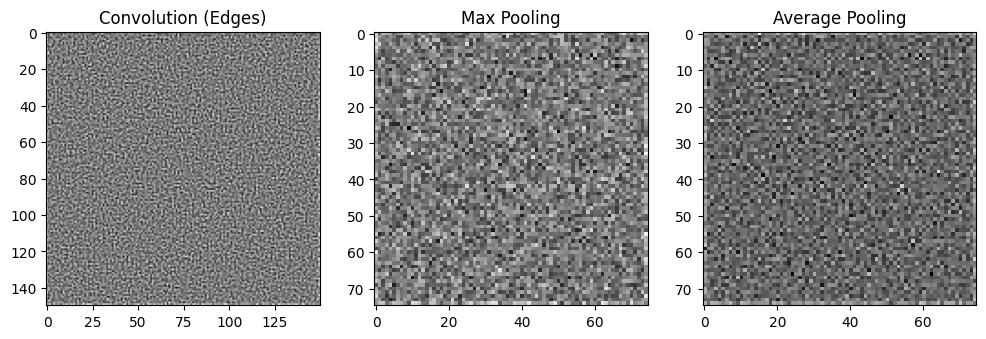

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
# task 1
img = np.random.rand(150, 150, 3).astype(np.float32) 

kernel = tf.constant([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=tf.float32)
kernel = tf.reshape(kernel, [3, 3, 1, 1])

gray_img = tf.image.rgb_to_grayscale(img)
gray_img = tf.expand_dims(gray_img, axis=0) # Add batch dimension

conv_result = tf.nn.conv2d(gray_img, kernel, strides=[1, 1, 1, 1], padding='SAME')

max_pool = tf.nn.max_pool2d(conv_result, ksize=2, strides=2, padding='SAME')
avg_pool = tf.nn.avg_pool2d(conv_result, ksize=2, strides=2, padding='SAME')

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(conv_result[0, :, :, 0], cmap='gray'); plt.title("Convolution (Edges)")
plt.subplot(1, 3, 2); plt.imshow(max_pool[0, :, :, 0], cmap='gray'); plt.title("Max Pooling")
plt.subplot(1, 3, 3); plt.imshow(avg_pool[0, :, :, 0], cmap='gray'); plt.title("Average Pooling")
plt.show()

In [2]:
# Task 2
from tensorflow.keras import layers, models, datasets

(train_images, train_labels), (test_images, test_labels) = datasets.fashion_mnist.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0
train_images = train_images.reshape((-1, 28, 28, 1))
test_images = test_images.reshape((-1, 28, 28, 1))

cnn_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(train_images, train_labels, epochs=5, validation_split=0.1)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8507 - loss: 0.4140 - val_accuracy: 0.8837 - val_loss: 0.3162
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9019 - loss: 0.2707 - val_accuracy: 0.9037 - val_loss: 0.2643
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9177 - loss: 0.2214 - val_accuracy: 0.9132 - val_loss: 0.2317
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9307 - loss: 0.1856 - val_accuracy: 0.9140 - val_loss: 0.2388
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9424 - loss: 0.1558 - val_accuracy: 0.9178 - val_loss: 0.2408


In [3]:
from tensorflow.keras import layers, models

def residual_block(x, filters, stride=1):
    shortcut = x

    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding='same')(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Conv2D(filters, (3, 3), strides=stride, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)


    x = layers.Conv2D(filters, (3, 3), strides=1, padding='same')(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x


inputs = layers.Input(shape=(224, 224, 3))

x = layers.Conv2D(64, (7, 7), strides=2, padding='same')(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)


for _ in range(3): 
    x = residual_block(x, 64)
# 128 filters
for i in range(4): 
    x = residual_block(x, 128, stride=2 if i==0 else 1)
# 256 filters
for i in range(6): 
    x = residual_block(x, 256, stride=2 if i==0 else 1)
# 512 filters
for i in range(3): 
    x = residual_block(x, 512, stride=2 if i==0 else 1)

x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x) 

resnet34 = models.Model(inputs, outputs, name="Custom_ResNet34")

print(f"Model Name: {resnet34.name}")
print(f"Total layers in model: {len(resnet34.layers)}")
print(f"Total trainable parameters: {resnet34.count_params():,}")


Model Name: Custom_ResNet34
Total layers in model: 125
Total trainable parameters: 21,315,338


In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras import layers, models

(train_ds, val_ds, test_ds), info = tfds.load(
    'tf_flowers',
    split=['train[:70%]', 'train[70%:85%]', 'train[85%:]'],
    with_info=True,
    as_supervised=True
)

num_classes = info.features['label'].num_classes 


IMG_SIZE = 299 

def format_image(image, label):

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
  
    image = preprocess_input(image) 
    return image, label

BATCH_SIZE = 32
train_ds = train_ds.map(format_image).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(format_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(format_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
base_model = Xception(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

base_model.trainable = False 

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

history = model.fit(train_ds, validation_data=val_ds, epochs=3)

test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Epoch 1/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.7676 - loss: 0.7620 - val_accuracy: 0.8657 - val_loss: 0.4439
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.8817 - loss: 0.3988 - val_accuracy: 0.9038 - val_loss: 0.3363
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.9039 - loss: 0.3222 - val_accuracy: 0.9038 - val_loss: 0.3061
18/18 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8836 - loss: 0.3267
Test Accuracy: 0.8836
Test Loss: 0.3267
